# Experiment 4: Multivariate Linear Regression
**Case Study:** Predict House Prices using Area, Bedrooms, and House Age (10-row assumed dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2a & 2b. Load Assumed Dataset (10 Rows), Preprocessing & Feature Selection

In [2]:
data = {
    'Area_sqft': [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 3200],
    'Bedrooms': [2, 2, 3, 3, 3, 4, 4, 4, 5, 5],
    'House_Age_Yrs': [15, 10, 12, 8, 5, 6, 4, 3, 2, 1],
    'Price_Lakhs': [50, 62, 74, 90, 105, 114, 130, 146, 158, 170]
}

df = pd.DataFrame(data)
print('Dataset shape:', df.shape)
print('\nFirst 5 rows:')
print(df.head().to_string(index=False))

print('\nMissing values:')
print(df.isnull().sum())

# Remove missing rows if any
df = df.dropna().copy()

# Select independent (X) and dependent (y) variables
features = ['Area_sqft', 'Bedrooms', 'House_Age_Yrs']
X = df[features]
y = df['Price_Lakhs']

print('\nSelected independent variables:', features)
print('Dependent variable: Price_Lakhs')
print('X shape:', X.shape)
print('y shape:', y.shape)

Dataset shape: (10, 4)

First 5 rows:
 Area_sqft  Bedrooms  House_Age_Yrs  Price_Lakhs
      1000         2             15           50
      1200         2             10           62
      1500         3             12           74
      1800         3              8           90
      2000         3              5          105

Missing values:
Area_sqft        0
Bedrooms         0
House_Age_Yrs    0
Price_Lakhs      0
dtype: int64

Selected independent variables: ['Area_sqft', 'Bedrooms', 'House_Age_Yrs']
Dependent variable: Price_Lakhs
X shape: (10, 3)
y shape: (10,)


### 2c & 2d. Train-Test Split & Train Multivariate Linear Regression Model

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print('Training samples:', len(X_train))
print('Testing samples :', len(X_test))

model = LinearRegression()
model.fit(X_train, y_train)

print('\nModel training completed successfully.')
print('Intercept:', model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print('\nRegression Coefficients:')
print(coefficients.to_string(index=False))

Training samples: 7
Testing samples : 3

Model training completed successfully.
Intercept: -4.576079734219249

Regression Coefficients:
      Feature  Coefficient
    Area_sqft     0.056874
     Bedrooms    -1.810963
House_Age_Yrs    -0.025748


### 2e & 2f. Predict Test Dataset, Model Evaluation Metrics & Plot

Prediction results:
 Actual  Predicted
    158 156.938870
     62  59.793023
    114 113.147841

Model Evaluation Metrics
-----------------------------------
R2 Score : 0.9985
MAE      : 1.3734
MSE      : 2.2410
RMSE     : 1.4970


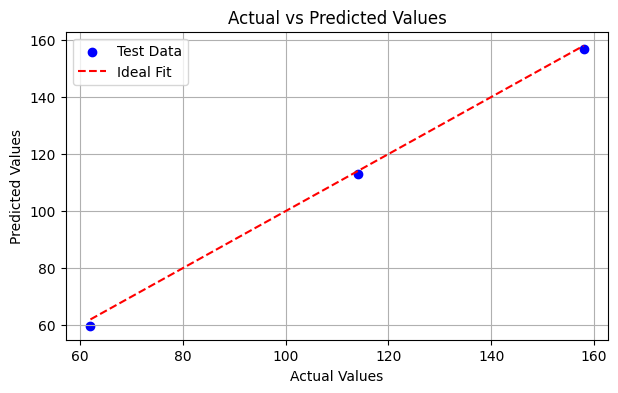

In [4]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
print('Prediction results:')
print(results.to_string(index=False))

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('\nModel Evaluation Metrics')
print('-' * 35)
print(f'R2 Score : {r2:.4f}')
print(f'MAE      : {mae:.4f}')
print(f'MSE      : {mse:.4f}')
print(f'RMSE     : {rmse:.4f}')

plt.figure(figsize=(7, 4))
plt.scatter(y_test, y_pred, color='blue', label='Test Data')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Ideal Fit')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.grid(True)
plt.show()

### 2g. Interpret Regression Coefficients

In [5]:
coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values('Absolute Coefficient', ascending=False)

print(coefficients[['Feature', 'Coefficient']].to_string(index=False))
print('\nInterpretation:')
for _, row in coefficients.iterrows():
    direction = 'positive' if row['Coefficient'] > 0 else 'negative'
    print(f"{row['Feature']}: {row['Coefficient']:.4f} -> {direction} relationship with the target, holding other features constant.")

      Feature  Coefficient
     Bedrooms    -1.810963
    Area_sqft     0.056874
House_Age_Yrs    -0.025748

Interpretation:
Bedrooms: -1.8110 -> negative relationship with the target, holding other features constant.
Area_sqft: 0.0569 -> positive relationship with the target, holding other features constant.
House_Age_Yrs: -0.0257 -> negative relationship with the target, holding other features constant.
